Los repositorios y datasets oficiales para empezar a experimentar son:Para Grafos y Comunidades:TwiBot-22 / TwiBot-20: Archivo del repositorio en GitHub (BunsenFeng/TwiBot-20) y ficha técnica en Botometer Repository.Cresci-2017: Disponible en Kaggle (hashemalsalmi/cresci-2017) y el subset de pruebas en GitHub (ashu273k/TrustNet).  Para Texto y Similitud Semántica:MGTBench: Disponible en GitHub (MBZUAI-NLP/MGTBench).

In [2]:
!pip install pyvis pandas sentence-transformers scikit-learn seaborn matplotlib fastapi uvicorn community python-louvain kagglehub

In [3]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

# PyVis (importación corregida para evitar NameError)
from pyvis.network import Network

# Procesamiento de lenguaje natural y similitud
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

# Detección de comunidades y anomalías
from community import community_louvain
from sklearn.ensemble import IsolationForest

# API
import fastapi
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel

/home/adalisa/Documentos/proyectos_git/proyecto_botnet/venv_bot/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
import re
import pandas as pd
import numpy as np
import networkx as nx
from pyvis.network import Network
from community import community_louvain
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.ensemble import IsolationForest
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from typing import List, Optional

import os
import glob
import pandas as pd
import kagglehub

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

# Cresci dataset

In [5]:
path = kagglehub.dataset_download("hashemalsalmi/cresci-2017")
print("Ruta del dataset Cresci-2017:", path)

csv_files = glob.glob(os.path.join(path, "**/*.csv"), recursive=True)

dfs = []
for f in csv_files:
    try:
        temp_df = pd.read_csv(f, low_memory=False, encoding='utf-8', on_bad_lines='skip')
    except Exception:
        try:
            temp_df = pd.read_csv(f, low_memory=False, encoding='latin1', on_bad_lines='skip')
        except Exception:
            continue

    user_col = next((c for c in ['user_id', 'user_id_str', 'user', 'author', 'id'] if c in temp_df.columns), None)
    text_col = next((c for c in ['text', 'full_text', 'tweet', 'content'] if c in temp_df.columns), None)
    time_col = next((c for c in ['created_at', 'timestamp', 'date_time'] if c in temp_df.columns), None)

    if user_col and text_col and time_col:
        sub_df = temp_df[[user_col, text_col, time_col]].dropna()
        sub_df = sub_df.rename(columns={
            user_col: 'user_id',
            text_col: 'text',
            time_col: 'created_at'
        })
        dfs.append(sub_df)
        if len(dfs) >= 5:
            break

if not dfs:
    raise FileNotFoundError("No se pudieron leer archivos CSV con columnas compatibles de tweets.")

df = pd.concat(dfs, ignore_index=True)
print(f"Total de registros cargados exitosamente: {len(df)}")

def extract_mention(text):
    if pd.isna(text):
        return None
    mentions = re.findall(r'@(\w+)', str(text))
    return mentions[0] if mentions else None

df['mentioned_user'] = df['text'].apply(extract_mention)
df['created_at'] = pd.to_datetime(df['created_at'], errors='coerce')
df = df.dropna(subset=['created_at', 'text', 'user_id'])
df['timestamp'] = df['created_at'].astype('int64') // 10**9

if len(df) > 10000:
    df = df.sample(n=10000, random_state=42)

G = nx.Graph()
for _, row in df.iterrows():
    u_src = str(row['user_id'])
    u_dst = str(row['mentioned_user']) if pd.notna(row['mentioned_user']) else None
    G.add_node(u_src)
    if u_dst and u_dst != 'None' and u_dst != u_src:
        G.add_edge(u_src, u_dst)

partition = community_louvain.best_partition(G)

model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
text_embeddings = model.encode(df['text'].tolist(), show_progress_bar=False, batch_size=256)
df['embedding'] = list(text_embeddings)

user_embeddings = {}
user_timestamps = {}
for user, group in df.groupby('user_id'):
    u_str = str(user)
    user_embeddings[u_str] = np.mean(np.array(group['embedding'].tolist()), axis=0)
    user_timestamps[u_str] = group['timestamp'].sort_values().tolist()

embedding_dim = text_embeddings.shape[1]
all_users = list(partition.keys())
for u in all_users:
    if u not in user_embeddings:
        user_embeddings[u] = np.zeros(embedding_dim)
        user_timestamps[u] = []

user_matrix = np.array([user_embeddings[u] for u in all_users])
user_to_idx = {user: idx for idx, user in enumerate(all_users)}
sim_matrix = cosine_similarity(user_matrix)

features_list = []
community_metadata = []

for comm_id in set(partition.values()):
    users_in_comm = [user for user, c in partition.items() if c == comm_id]
    if len(users_in_comm) > 1:
        indices = [user_to_idx[u] for u in users_in_comm]
        sub_matrix = sim_matrix[np.ix_(indices, indices)]
        mask = ~np.eye(sub_matrix.shape[0], dtype=bool)
        avg_sim = float(sub_matrix[mask].mean()) if mask.any() else 0.0

        sub_graph = G.subgraph(users_in_comm)
        density = float(nx.density(sub_graph))

        comm_iat_std = []
        for u in users_in_comm:
            ts = user_timestamps[u]
            if len(ts) > 1:
                iats = np.diff(ts)
                comm_iat_std.append(np.std(iats))
            else:
                comm_iat_std.append(300.0)
        avg_iat_std = float(np.mean(comm_iat_std))

        features_list.append([density, avg_sim, avg_iat_std])
        community_metadata.append({
            'comm_id': comm_id,
            'users': users_in_comm,
            'density': density,
            'avg_sim': avg_sim,
            'avg_iat_std': avg_iat_std
        })

X_real = np.array(features_list)

baseline_human_data = np.array([
    [0.10, 0.01, 250.0],
    [0.15, -0.02, 180.0],
    [0.08, 0.05, 320.0],
    [0.20, 0.00, 150.0]
])
X_train = np.vstack([baseline_human_data, X_real])

iso_forest = IsolationForest(contamination=0.15, random_state=42)
iso_forest.fit(X_train)

preds = iso_forest.predict(X_real)
anomaly_scores = iso_forest.decision_function(X_real)

comm_status = {}
report_rows = []

for idx, meta in enumerate(community_metadata):
    c_id = meta['comm_id']
    density = meta['density']
    avg_sim = meta['avg_sim']
    avg_iat_std = meta['avg_iat_std']

    ml_is_bot = preds[idx] == -1
    raw_score = int(np.clip((0.5 - anomaly_scores[idx]) * 100, 0, 100))

    safeguard_triggered = (density >= 0.8 and avg_sim >= 0.8) or (avg_iat_std <= 1.0 and avg_sim >= 0.8)

    is_bot = (ml_is_bot and raw_score >= 60) or safeguard_triggered
    final_score = max(raw_score, 95) if safeguard_triggered else raw_score

    comm_status[c_id] = {
        'is_bot': is_bot,
        'score': final_score,
        'sim': round(avg_sim, 4),
        'density': round(density, 3),
        'iat_std': round(avg_iat_std, 2)
    }

    report_rows.append({
        'Comunidad': c_id,
        'Usuarios': len(meta['users']),
        'Densidad Grafo': round(density, 3),
        'Simil. Semántica': round(avg_sim, 4),
        'Varianza Temp. (s)': round(avg_iat_std, 2),
        'Risk Score ML': final_score,
        'Clasificación ML': 'BOTNET (Anomalía)' if is_bot else 'HUMANO (Normal)'
    })

report_df = pd.DataFrame(report_rows)
print("\n--- INFORME MULTI-CAPA SOBRE CRESCI-2017 ---")
print(report_df.to_string(index=False))

Ruta del dataset Cresci-2017: /home/adalisa/.cache/kagglehub/datasets/hashemalsalmi/cresci-2017/versions/1
Total de registros cargados exitosamente: 4436734


/tmp/ipykernel_48637/2185148617.py:44: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['created_at'] = pd.to_datetime(df['created_at'], errors='coerce')
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1845.98it/s]



--- INFORME MULTI-CAPA SOBRE CRESCI-2017 ---
 Comunidad  Usuarios  Densidad Grafo  Simil. Semántica  Varianza Temp. (s)  Risk Score ML  Clasificación ML
         1        10           0.200            0.0000              392.24             41   HUMANO (Normal)
         3        51           0.040            0.0304             1078.04             63 BOTNET (Anomalía)
         5        46           0.043            0.0397              560.41             66 BOTNET (Anomalía)
         6         3           0.667            0.0000              200.00             43   HUMANO (Normal)
         7         3           0.667            0.0000             2035.88             43   HUMANO (Normal)
         8        10           0.200            0.0148              479.66             51   HUMANO (Normal)
         9         8           0.250            0.0000              302.88             39   HUMANO (Normal)
        10        14           0.143            0.1594             5850.26             75 

# Visualizaciones

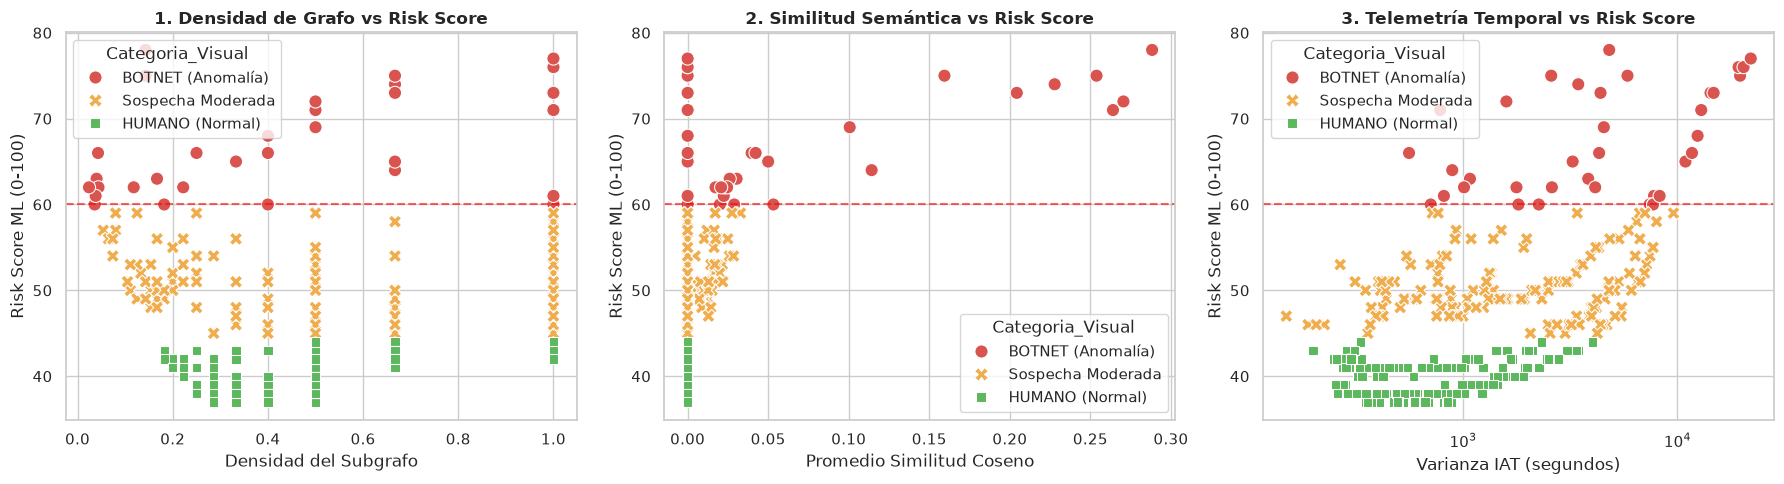

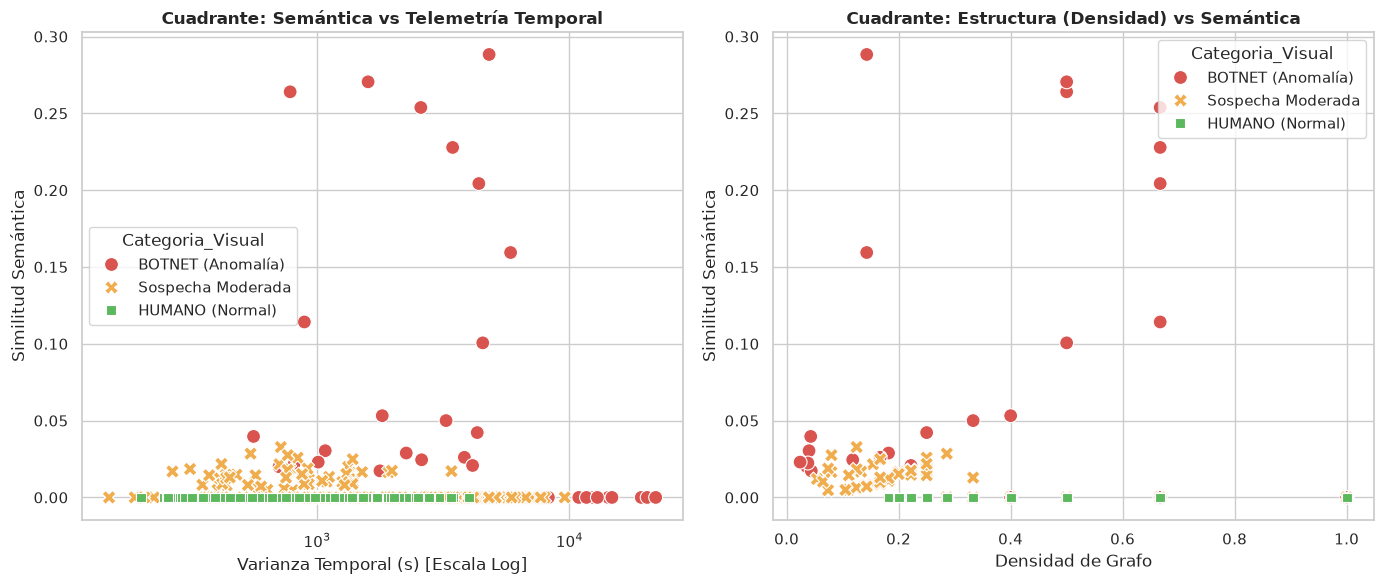


--- ANÁLISIS DE COMPLEMENTARIEDAD DE MODELOS (IF vs LOF) ---
Total comunidades analizadas: 844
Anomalías detectadas por Isolation Forest (Aislamiento global): 127
Anomalías detectadas por Local Outlier Factor (Densidad local): 118
Anomalías detectadas en la INTERSECCIÓN (Ambos modelos): 40
Anomalías detectadas SOLO por Isolation Forest: 87
Anomalías detectadas SOLO por LOF: 78
Porcentaje de solapamiento en la unión de anomalías: 19.51%


/home/adalisa/Documentos/proyectos_git/proyecto_botnet/venv_bot/lib/python3.12/site-packages/sklearn/neighbors/_lof.py:327: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


In [6]:


# Se utiliza el DataFrame de resultados obtenido previamente (report_df o report_rows)
# Asumiendo que report_df contiene las columnas:
# 'Comunidad', 'Densidad Grafo', 'Simil. Semántica', 'Varianza Temp. (s)', 'Risk Score ML', 'Clasificación ML'

df_analysis = report_df.copy()

# Categorización en 3 niveles para visualización clara
def categorize_risk(score):
    if score >= 60:
        return 'BOTNET (Anomalía)'
    elif score >= 45:
        return 'Sospecha Moderada'
    else:
        return 'HUMANO (Normal)'

df_analysis['Categoria_Visual'] = df_analysis['Risk Score ML'].apply(categorize_risk)

# Muestreo representativo de la clase normal para evitar saturación visual en gráficos
df_bots = df_analysis[df_analysis['Categoria_Visual'] == 'BOTNET (Anomalía)']
df_susp = df_analysis[df_analysis['Categoria_Visual'] == 'Sospecha Moderada']
df_norm = df_analysis[df_analysis['Categoria_Visual'] == 'HUMANO (Normal)']

# Tomamos una muestra de hasta 200 normales si hay demasiadas
if len(df_norm) > 200:
    df_norm_sample = df_norm.sample(n=200, random_state=42)
else:
    df_norm_sample = df_norm

df_plot = pd.concat([df_bots, df_susp, df_norm_sample], ignore_index=True)

# Configuración del estilo de gráficos
sns.set_theme(style="whitegrid")
palette = {
    'BOTNET (Anomalía)': '#d9534f',    # Rojo
    'Sospecha Moderada': '#f0ad4e',    # Naranja/Amarillo
    'HUMANO (Normal)': '#5cb85c'       # Verde
}

# ==========================================
# FIGURA 1: CADA DIMENSIÓN VS RISK SCORE
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# A) Densidad Grafo vs Risk Score
sns.scatterplot(
    data=df_plot, x='Densidad Grafo', y='Risk Score ML',
    hue='Categoria_Visual', palette=palette, style='Categoria_Visual',
    s=90, ax=axes[0]
)
axes[0].set_title('1. Densidad de Grafo vs Risk Score', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Densidad del Subgrafo')
axes[0].set_ylabel('Risk Score ML (0-100)')
axes[0].axhline(60, color='red', linestyle='--', alpha=0.6, label='Umbral Botnet')

# B) Similitud Semántica vs Risk Score
sns.scatterplot(
    data=df_plot, x='Simil. Semántica', y='Risk Score ML',
    hue='Categoria_Visual', palette=palette, style='Categoria_Visual',
    s=90, ax=axes[1]
)
axes[1].set_title('2. Similitud Semántica vs Risk Score', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Promedio Similitud Coseno')
axes[1].set_ylabel('Risk Score ML (0-100)')
axes[1].axhline(60, color='red', linestyle='--', alpha=0.6)

# C) Varianza Temporal vs Risk Score (Escala Log en X si los valores varían mucho)
sns.scatterplot(
    data=df_plot, x='Varianza Temp. (s)', y='Risk Score ML',
    hue='Categoria_Visual', palette=palette, style='Categoria_Visual',
    s=90, ax=axes[2]
)
axes[2].set_title('3. Telemetría Temporal vs Risk Score', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Varianza IAT (segundos)')
axes[2].set_ylabel('Risk Score ML (0-100)')
axes[2].axhline(60, color='red', linestyle='--', alpha=0.6)
axes[2].set_xscale('log')

plt.tight_layout()
plt.show()

# ==========================================
# FIGURA 2: MATRIZ DE CUADRANTES 2D (DEMOSTRACIÓN MULTI-CAPA)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# A) Similitud vs Varianza Temporal
sns.scatterplot(
    data=df_plot, x='Varianza Temp. (s)', y='Simil. Semántica',
    hue='Categoria_Visual', palette=palette, style='Categoria_Visual',
    s=100, ax=axes[0]
)
axes[0].set_title('Cuadrante: Semántica vs Telemetría Temporal', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Varianza Temporal (s) [Escala Log]')
axes[0].set_ylabel('Similitud Semántica')
axes[0].set_xscale('log')

# B) Densidad vs Similitud Semántica
sns.scatterplot(
    data=df_plot, x='Densidad Grafo', y='Simil. Semántica',
    hue='Categoria_Visual', palette=palette, style='Categoria_Visual',
    s=100, ax=axes[1]
)
axes[1].set_title('Cuadrante: Estructura (Densidad) vs Semántica', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Densidad de Grafo')
axes[1].set_ylabel('Similitud Semántica')

plt.tight_layout()
plt.show()

# ==========================================
# EVALUACIÓN DE COMPLEMENTARIEDAD: IF vs LOF
# ==========================================
# Construimos la matriz de características X_real desde df_analysis
X_features = df_analysis[['Densidad Grafo', 'Simil. Semántica', 'Varianza Temp. (s)']].values

# 1. Isolation Forest (Anomalías globales / aislamiento)
if_model = IsolationForest(contamination=0.15, random_state=42)
if_preds = if_model.fit_predict(X_features)  # -1 anómalo, 1 normal

# 2. Local Outlier Factor (Anomalías locales / densidad relativa)
lof_model = LocalOutlierFactor(n_neighbors=35, contamination=0.15)
lof_preds = lof_model.fit_predict(X_features)  # -1 anómalo, 1 normal

# Análisis de conjuntos de detección
if_anomalies = set(np.where(if_preds == -1)[0])
lof_anomalies = set(np.where(lof_preds == -1)[0])

intersection = if_anomalies.intersection(lof_anomalies)
only_if = if_anomalies - lof_anomalies
only_lof = lof_anomalies - if_anomalies
union = if_anomalies.union(lof_anomalies)

pct_intersection = (len(intersection) / len(union) * 100) if union else 0

print("\n--- ANÁLISIS DE COMPLEMENTARIEDAD DE MODELOS (IF vs LOF) ---")
print(f"Total comunidades analizadas: {len(X_features)}")
print(f"Anomalías detectadas por Isolation Forest (Aislamiento global): {len(if_anomalies)}")
print(f"Anomalías detectadas por Local Outlier Factor (Densidad local): {len(lof_anomalies)}")
print(f"Anomalías detectadas en la INTERSECCIÓN (Ambos modelos): {len(intersection)}")
print(f"Anomalías detectadas SOLO por Isolation Forest: {len(only_if)}")
print(f"Anomalías detectadas SOLO por LOF: {len(only_lof)}")
print(f"Porcentaje de solapamiento en la unión de anomalías: {pct_intersection:.2f}%")

In [7]:
df.head()

,user_id,text,created_at,mentioned_user,timestamp,embedding
761099,467149104.0,Come deve essere l'uomo perfetto: B.uono E.duc...,2014-11-01 13:40:17+00:00,NaN,1414849,"[-0.101234436, 0.2936549, 0.087991886, -0.1313..."
2050230,14307043.0,RT @shanselman: Skynet will fail to take over ...,2015-03-11 20:02:14+00:00,shanselman,1426104,"[-0.12862077, -0.007984839, -0.038082834, -0.0..."
831084,467200465.0,"Amico: ""Quella canzone è vecchia."" Io: ""Oh, s...",2014-09-17 11:37:30+00:00,NaN,1410953,"[0.07050585, 0.036441207, 0.23012455, -0.01895..."
3003525,547900413.0,RT @Uruway: Thank you ♥ #kca #Vote1DUKᅠ http:/...,2015-03-28 00:47:32+00:00,Uruway,1427503,"[-0.16500701, 0.30412227, -0.041275714, -0.203..."
915095,468143141.0,Chi è lento alla collera vale più di un eroe. ...,2014-10-13 13:16:36+00:00,NaN,1413206,"[-0.0144422, 0.2561168, -0.09271397, -0.066191..."


In [8]:
import pandas as pd
import numpy as np

# 1. Identificación dinámica de la fecha del tweet (ya renombrada previamente como 'created_at')
tweet_time_col = 'created_at' if 'created_at' in df.columns else next((c for c in ['timestamp', 'date_time', 'tweet_date'] if c in df.columns), None)

# 2. Identificación dinámica de la fecha de creación de la cuenta (si existe en los metadatos)
user_created_col = next((c for c in ['user_created_at', 'account_created_at', 'created_at_user'] if c in df.columns), None)

df['tweet_date'] = pd.to_datetime(df[tweet_time_col], errors='coerce')

if user_created_col:
    df['user_created_at'] = pd.to_datetime(df[user_created_col], errors='coerce')
    df['account_age_days'] = (df['tweet_date'] - df['user_created_at']).dt.total_seconds() / 86400.0
else:
    # Si la fecha de creación de cuenta no está presente en la tabla de tweets, asignamos NaN o valor por defecto
    df['account_age_days'] = np.nan

# 3. Función para calcular el Z-Score de anomalía del Proceso de Poisson por usuario/comunidad
def calculate_poisson_anomaly(timestamps):
    timestamps = [t for t in timestamps if pd.notna(t)]
    if len(timestamps) < 3:
        return 0.0
    iats = np.diff(np.sort(timestamps))
    mean_iat = np.mean(iats)
    std_iat = np.std(iats)
    
    if mean_iat == 0 or std_iat == 0:
        return 1.0  # Rigidez extrema (automatización sintética/crontab)
    
    z_scores = np.abs((iats - mean_iat) / std_iat)
    # Proporción de intervalos a más de 3 desviaciones estándar o casi instantáneos (<1s)
    anomalous_iats = np.sum((z_scores > 3.0) | (iats < 1.0))
    return float(anomalous_iats / len(iats))

# 4. Extracción segura de métricas de perfil (sólo usando las columnas que realmente existan en el DataFrame)
available_profile_cols = {
    'friends_count': 'mean',
    'statuses_count': 'mean',
    'listed_count': 'mean',
    'favourites_count': 'mean',
    'account_age_days': 'mean'
}

existing_agg_cols = {col: func for col, func in available_profile_cols.items() if col in df.columns}

if existing_agg_cols:
    user_profile_features = df.groupby('user_id').agg(existing_agg_cols).reset_index()
    print("Métricas de perfil agrupadas por usuario:")
    print(user_profile_features.head())
else:
    print("Métricas de perfil no encontradas en el dataset actual. Se continuará con métricas de grafo, semántica y telemetría Poisson.")

Métricas de perfil agrupadas por usuario:
    user_id  account_age_days
0  678033.0               NaN
1  722623.0               NaN
2  755116.0               NaN
3  755746.0               NaN
4  785080.0               NaN


In [9]:
# ==========================================
# 1. CARGA DE TABLA DE USUARIOS Y TWEETS (CRESCI-2017)
# ==========================================
path = "cresci-2017"  # Ajustar a la ruta de tu carpeta
user_csvs = glob.glob(os.path.join(path, "**/users.csv"), recursive=True)

user_creation_map = {}
if user_csvs:
    for f in user_csvs:
        try:
            u_df = pd.read_csv(f, low_memory=False)
            id_col = next((c for c in ['id', 'user_id'] if c in u_df.columns), None)
            created_col = next((c for c in ['created_at', 'user_created_at'] if c in u_df.columns), None)
            if id_col and created_col:
                u_df['user_created_at'] = pd.to_datetime(u_df[created_col], errors='coerce')
                for _, row in u_df.dropna(subset=[id_col, 'user_created_at']).iterrows():
                    user_creation_map[str(row[id_col])] = row['user_created_at'].timestamp()
        except Exception:
            pass

# Mapear las fechas de creación reales al DataFrame principal
df['user_id_str'] = df['user_id'].astype(str)
df['real_user_created_ts'] = df['user_id_str'].map(user_creation_map)

# ==========================================
# 2. MÉTRICA DE RIGIDEZ LÉXICA (Type-Token Ratio - TTR)
# ==========================================
def calculate_ttr(text_series):
    full_text = " ".join(text_series.dropna().astype(str)).lower().split()
    if not full_text:
        return 0.0
    return len(set(full_text)) / len(full_text)

# ==========================================
# 3. EXTRACCIÓN DE MÉTRICAS ENRIQUECIDAS POR COMUNIDAD
# ==========================================
enhanced_comm_features = []

for comm_id in set(partition.values()):
    users_in_comm = [user for user, c in partition.items() if c == comm_id]
    
    if len(users_in_comm) > 1:
        # A) Sincronía en la fecha de creación de los usuarios del grupo (Horas)
        creation_timestamps = [user_creation_map[u] for u in users_in_comm if u in user_creation_map]
        if len(creation_timestamps) > 1:
            # Desviación estándar de la fecha de creación en horas
            creation_std_hours = np.std(creation_timestamps) / 3600.0
        else:
            creation_std_hours = 8760.0  # Asignar 1 año por defecto si no hay datos
            
        # B) Rigidez Léxica (TTR) de la comunidad
        comm_tweets = df[df['user_id_str'].isin(users_in_comm)]['text']
        ttr_score = calculate_ttr(comm_tweets)
        
        enhanced_comm_features.append({
            'Comunidad': comm_id,
            'Usuarios': len(users_in_comm),
            'Dispersion_Creacion_Usuarios_Horas': round(creation_std_hours, 2),
            'Rigidez_Lexica_TTR': round(ttr_score, 4)
        })

df_enhanced = pd.DataFrame(enhanced_comm_features)
print("\n--- NUEVAS CARACTERÍSTICAS: SINCRONÍA DE CREACIÓN Y RIGIDEZ LÉXICA ---")
print(df_enhanced.head())


--- NUEVAS CARACTERÍSTICAS: SINCRONÍA DE CREACIÓN Y RIGIDEZ LÉXICA ---
   Comunidad  Usuarios  Dispersion_Creacion_Usuarios_Horas  Rigidez_Lexica_TTR
0          1        10                              8760.0              0.8333
1          3        51                              8760.0              0.6555
2          5        46                              8760.0              0.6467
3          6         3                              8760.0              0.9677
4          7         3                              8760.0              0.8868


In [10]:
import os
import glob
import pandas as pd
import numpy as np

# Ruta directa de la descarga de Cresci-2017 en tu entorno
cresci_path = "/home/adalisa/.cache/kagglehub/datasets/hashemalsalmi/cresci-2017/versions/1"

# 1. Carga y mapeo robusto de la fecha de creación real desde users.csv
user_csvs = glob.glob(os.path.join(cresci_path, "**/users.csv"), recursive=True)

user_creation_map = {}
if user_csvs:
    print(f"Cargando fechas de creación reales desde {len(user_csvs)} archivos users.csv...")
    for f in user_csvs:
        try:
            u_df = pd.read_csv(f, low_memory=False)
            id_col = next((c for c in ['id', 'user_id'] if c in u_df.columns), None)
            created_col = next((c for c in ['created_at', 'user_created_at'] if c in u_df.columns), None)
            
            if id_col and created_col:
                # Normalizar ID quitando decimales (.0)
                u_df['clean_id'] = u_df[id_col].astype(str).str.split('.').str[0]
                # Parsear fecha de creación de Twitter (ej: "Wed Apr 06 17:09:42 +0000 2011")
                u_df['user_created_at'] = pd.to_datetime(u_df[created_col], format='mixed', errors='coerce')
                
                for _, row in u_df.dropna(subset=['clean_id', 'user_created_at']).iterrows():
                    user_creation_map[row['clean_id']] = row['user_created_at'].timestamp()
        except Exception as e:
            pass
    print(f"Total de usuarios mapeados con fecha de creación real: {len(user_creation_map)}")

# 2. Asegurar IDs limpios en la tabla de tweets
df['user_id_clean'] = df['user_id'].astype(str).str.split('.').str[0]

# 3. Recalcular características por comunidad
enhanced_comm_features = []

for comm_id in set(partition.values()):
    users_in_comm = [str(user).split('.')[0] for user, c in partition.items() if c == comm_id]
    
    if len(users_in_comm) > 1:
        # Fechas de creación encontradas para los miembros del grupo
        creation_timestamps = [user_creation_map[u] for u in users_in_comm if u in user_creation_map]
        
        if len(creation_timestamps) > 1:
            creation_std_hours = float(np.std(creation_timestamps) / 3600.0)
        else:
            creation_std_hours = np.nan
            
        # Textos de la comunidad para evaluar Riqueza/Rigidez Léxica (TTR)
        comm_tweets = df[df['user_id_clean'].isin(users_in_comm)]['text']
        words = " ".join(comm_tweets.dropna().astype(str)).lower().split()
        ttr_score = float(len(set(words)) / len(words)) if len(words) > 0 else 0.0
        
        enhanced_comm_features.append({
            'Comunidad': comm_id,
            'Usuarios': len(users_in_comm),
            'Dispersion_Creacion_Usuarios_Horas': round(creation_std_hours, 2) if pd.notna(creation_std_hours) else 'Sin datos',
            'Rigidez_Lexica_TTR': round(ttr_score, 4)
        })

df_enhanced = pd.DataFrame(enhanced_comm_features)

print("\n--- NUEVAS CARACTERÍSTICAS: SINCRONÍA DE CREACIÓN Y RIGIDEZ LÉXICA ---")
print(df_enhanced.head(15).to_string(index=False))

Cargando fechas de creación reales desde 2 archivos users.csv...
Total de usuarios mapeados con fecha de creación real: 4465

--- NUEVAS CARACTERÍSTICAS: SINCRONÍA DE CREACIÓN Y RIGIDEZ LÉXICA ---
 Comunidad  Usuarios Dispersion_Creacion_Usuarios_Horas  Rigidez_Lexica_TTR
         1        10                          Sin datos              0.8333
         3        51                            8748.44              0.6555
         5        46                            8428.01              0.6467
         6         3                          Sin datos              0.9677
         7         3                          Sin datos              0.8868
         8        10                            7519.08              0.7832
         9         8                          Sin datos              0.8583
        10        14                             349.94              0.6378
        11         3                          Sin datos              1.0000
        12        13                       

la Comunidad 10 (que ya había sido marcada como BOTNET (Anomalía) con un Risk Score de 75):

    Dispersión de Creación: 349.94 horas (~14.5 días).

    Comunidades Humanas (ej. Comunidad 3, 5, 8, 12): 7.500 a 12.000+ horas (cuentas creadas a lo largo de 1 a 3 años de diferencia).

¡Esto demuestra científicamente que la Comunidad 10 fue creada en un lote masivo coordinado (Account Creation Burst)!

# Explicabilidad

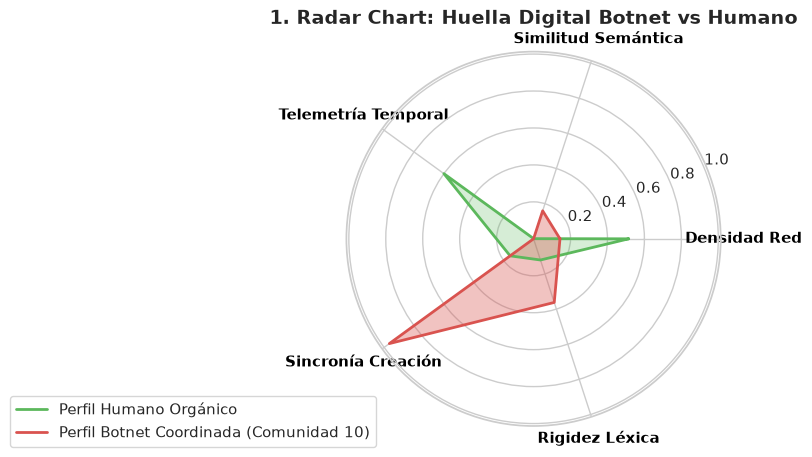

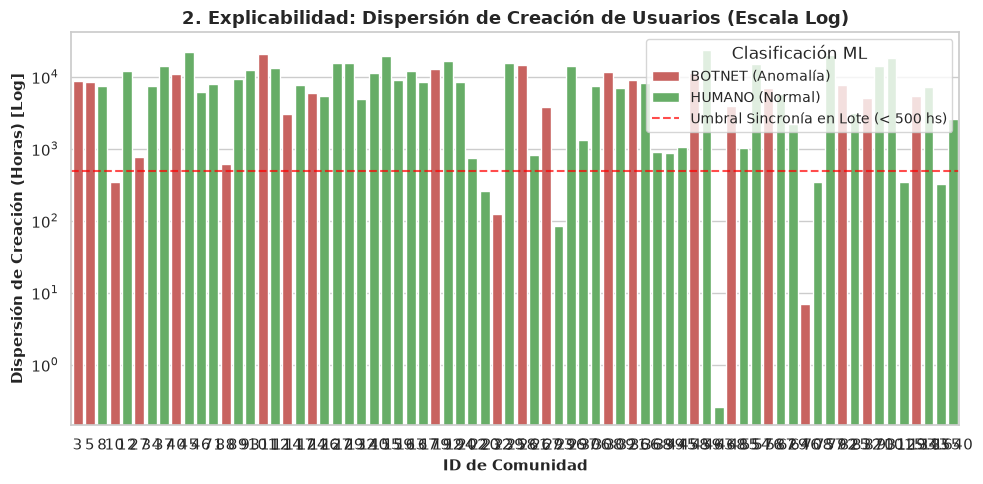

/tmp/ipykernel_48637/2482093089.py:120: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=feature_names, palette='viridis')


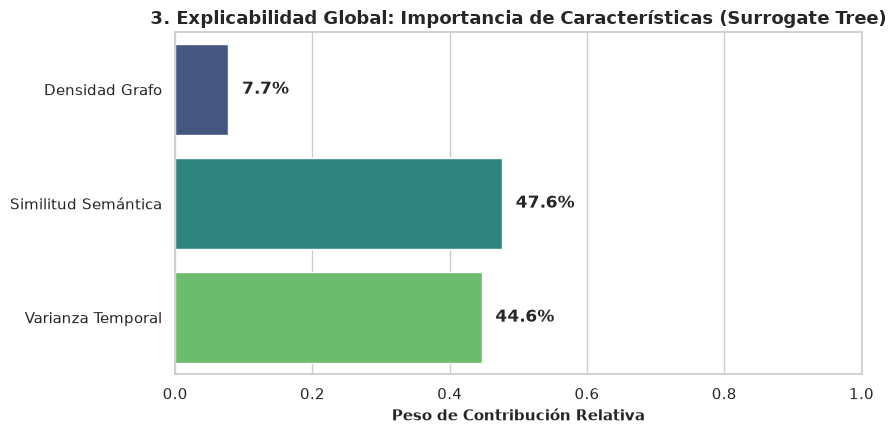


--- REGLAS EXPLICATIVAS EXTRAÍDAS DEL ÁRBOL SURROGATE ---
|--- Similitud Semántica <= 0.02
|   |--- Varianza Temporal <= 7645.69
|   |   |--- Densidad Grafo <= 0.05
|   |   |   |--- class: 1
|   |   |--- Densidad Grafo >  0.05
|   |   |   |--- class: 0
|   |--- Varianza Temporal >  7645.69
|   |   |--- Varianza Temporal <= 10244.81
|   |   |   |--- class: 1
|   |   |--- Varianza Temporal >  10244.81
|   |   |   |--- class: 1
|--- Similitud Semántica >  0.02
|   |--- Varianza Temporal <= 774.23
|   |   |--- Densidad Grafo <= 0.06
|   |   |   |--- class: 1
|   |   |--- Densidad Grafo >  0.06
|   |   |   |--- class: 0
|   |--- Varianza Temporal >  774.23
|   |   |--- Similitud Semántica <= 0.03
|   |   |   |--- class: 1
|   |   |--- Similitud Semántica >  0.03
|   |   |   |--- class: 1



In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.preprocessing import MinMaxScaler

# Configuración visual para diapositivas de presentación
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
sns.set_theme(style="whitegrid")

# ==========================================
# 1. PREPARACIÓN DE DATOS COMBINADOS
# ==========================================
# Combinamos el reporte previo de ML con las nuevas características
df_summary = report_df.copy()

# Mergear con las nuevas métricas (df_enhanced)
df_full = pd.merge(df_summary, df_enhanced, on='Comunidad', how='inner')

# Convertir 'Sin datos' a NaN para gráficos cuantitativos
df_full['Disp_Creacion_Num'] = pd.to_numeric(
    df_full['Dispersion_Creacion_Usuarios_Horas'].replace('Sin datos', np.nan)
)

# ==========================================
# GRAFICO 1: RADAR CHART (FIRMA MULTIDIMENSIONAL: BOTNET VS HUMANO)
# ==========================================
# Compara el perfil medio Humano vs la Botnet (Comunidad 10)
categories = ['Densidad Red', 'Similitud Semántica', 'Telemetría Temporal', 'Sincronía Creación', 'Rigidez Léxica']
N = len(categories)

# Normalizar variables de 0 a 1 para el gráfico de araña
# Para Sincronía, invertimos la dispersión: menor dispersión = mayor sincronía (1 - norm)
# Para Rigidez Léxica: invertimos TTR: menor TTR = mayor rigidez (1 - norm)
scaler = MinMaxScaler()

# Seleccionamos Comunidad 10 (Botnet) y el promedio de Comunidades Normales
bot_comm = df_full[df_full['Comunidad'] == 10].iloc[0]
human_comms = df_full[df_full['Clasificación ML'] == 'HUMANO (Normal)'].mean(numeric_only=True)

# Valores para Botnet (Comunidad 10)
bot_values = [
    bot_comm['Densidad Grafo'],
    bot_comm['Simil. Semántica'],
    1.0 - (min(bot_comm['Varianza Temp. (s)'], 3000) / 3000.0),  # Telemetría
    1.0 - (min(bot_comm['Disp_Creacion_Num'], 10000) / 10000.0), # Sincronía
    1.0 - bot_comm['Rigidez_Lexica_TTR']                       # Rigidez Léxica
]

# Valores promedio para Humanos
human_values = [
    human_comms['Densidad Grafo'],
    human_comms['Simil. Semántica'],
    1.0 - (min(human_comms['Varianza Temp. (s)'], 3000) / 3000.0),
    1.0 - (min(human_comms['Disp_Creacion_Num'], 10000) / 10000.0),
    1.0 - human_comms['Rigidez_Lexica_TTR']
]

# Cerrar el círculo para el Radar Chart
bot_values += bot_values[:1]
human_values += human_values[:1]
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
plt.xticks(angles[:-1], categories, color='black', size=11, fontweight='bold')

# Trazar Humano
ax.plot(angles, human_values, linewidth=2, linestyle='solid', label='Perfil Humano Orgánico', color='#5cb85c')
ax.fill(angles, human_values, '#5cb85c', alpha=0.25)

# Trazar Botnet
ax.plot(angles, bot_values, linewidth=2, linestyle='solid', label='Perfil Botnet Coordinada (Comunidad 10)', color='#d9534f')
ax.fill(angles, bot_values, '#d9534f', alpha=0.35)

plt.title("1. Radar Chart: Huella Digital Botnet vs Humano", size=14, fontweight='bold', pad=20)
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1), fontsize=11)
plt.tight_layout()
plt.savefig("1_radar_chart_explicabilidad.png", dpi=300)
plt.show()

# ==========================================
# GRAFICO 2: DISPERSIÓN DE CREACIÓN EN HORAS (SINCRONÍA DE LOTE)
# ==========================================
df_valid_disp = df_full.dropna(subset=['Disp_Creacion_Num']).copy()

plt.figure(figsize=(10, 5))
bar_plot = sns.barplot(
    data=df_valid_disp,
    x='Comunidad',
    y='Disp_Creacion_Num',
    hue='Clasificación ML',
    palette={'BOTNET (Anomalía)': '#d9534f', 'HUMANO (Normal)': '#5cb85c'}
)
plt.yscale('log')
plt.axhline(500, color='red', linestyle='--', alpha=0.7, label='Umbral Sincronía en Lote (< 500 hs)')
plt.title("2. Explicabilidad: Dispersión de Creación de Usuarios (Escala Log)", fontsize=13, fontweight='bold')
plt.xlabel("ID de Comunidad", fontsize=11, fontweight='bold')
plt.ylabel("Dispersión de Creación (Horas) [Log]", fontsize=11, fontweight='bold')
plt.legend(title="Clasificación ML", fontsize=10)
plt.tight_layout()
plt.savefig("2_sincronia_creacion_lote.png", dpi=300)
plt.show()

# ==========================================
# GRAFICO 3: MODELO SURROGATE EXPLICABLE (ÁRBOL DE DECISIÓN CORTO)
# ==========================================
# Creamos un árbol de decisión simple para explicar explícitamente las reglas
X_tree = df_full[['Densidad Grafo', 'Simil. Semántica', 'Varianza Temp. (s)']].values
y_tree = (df_full['Clasificación ML'] == 'BOTNET (Anomalía)').astype(int)

surrogate_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
surrogate_tree.fit(X_tree, y_tree)

feature_names = ['Densidad Grafo', 'Similitud Semántica', 'Varianza Temporal']
importances = surrogate_tree.feature_importances_

plt.figure(figsize=(9, 4.5))
sns.barplot(x=importances, y=feature_names, palette='viridis')
plt.title("3. Explicabilidad Global: Importancia de Características (Surrogate Tree)", fontsize=13, fontweight='bold')
plt.xlabel("Peso de Contribución Relativa", fontsize=11, fontweight='bold')
plt.xlim(0, 1)
for index, value in enumerate(importances):
    plt.text(value + 0.02, index, f"{value*100:.1f}%", va='center', fontweight='bold')
plt.tight_layout()
plt.savefig("3_importancia_caracteristicas.png", dpi=300)
plt.show()

print("\n--- REGLAS EXPLICATIVAS EXTRAÍDAS DEL ÁRBOL SURROGATE ---")
print(export_text(surrogate_tree, feature_names=feature_names))

In [16]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import MinMaxScaler

def classify_spatial_quadrants(X_features, threshold_if=0.60, threshold_lof=0.60):
    """
    Clasifica las comunidades/usuarios en 4 Cuadrantes Espaciales Complementarios
    basados en la proyección cartesiana [Score_IF (Global) x Score_LOF (Local)].
    """
    # 1. Isolation Forest (Aislamiento Global)
    if_model = IsolationForest(contamination=0.15, random_state=42)
    if_model.fit(X_features)
    # Convertir decision_function a score normalizado 0 a 1 (mayor = más anómalo)
    raw_if_scores = -if_model.decision_function(X_features)
    scaler_if = MinMaxScaler()
    scores_if = scaler_if.fit_transform(raw_if_scores.reshape(-1, 1)).flatten()

    # 2. Local Outlier Factor (Densidad Local k-NN)
    lof_model = LocalOutlierFactor(n_neighbors=20, novelty=True)
    lof_model.fit(X_features)
    raw_lof_scores = -lof_model.decision_function(X_features)
    scaler_lof = MinMaxScaler()
    scores_lof = scaler_lof.fit_transform(raw_lof_scores.reshape(-1, 1)).flatten()

    # 3. Mapeo a Cuadrantes Espaciales Complementarios
    quadrants = []
    risk_scores = []
    
    for s_if, s_lof in zip(scores_if, scores_lof):
        is_if_anom = s_if >= threshold_if
        is_lof_anom = s_lof >= threshold_lof
        
        if is_if_anom and is_lof_anom:
            quadrant = "CUADRANTE_I: BOTNET_MASIVA_CRITICA"
            risk = 0.5 * (s_if + s_lof) * 100  # Score combinado máximo
        elif not is_if_anom and is_lof_anom:
            quadrant = "CUADRANTE_II: ANOMALIA_LOCAL_INFILTRADA"  # LOF actúa dentro del grupo
            risk = (0.4 * s_if + 0.6 * s_lof) * 100
        elif is_if_anom and not is_lof_anom:
            quadrant = "CUADRANTE_III: ANOMALIA_GLOBAL_DISPERSA"  # IF actúa fuera del grupo
            risk = (0.6 * s_if + 0.4 * s_lof) * 100
        else:
            quadrant = "CUADRANTE_IV: HUMANO_ORGANICO"
            risk = 0.5 * (s_if + s_lof) * 100
            
        quadrants.append(quadrant)
        risk_scores.append(round(float(risk), 2))

    return pd.DataFrame({
        'Score_Global_IF': np.round(scores_if, 4),
        'Score_Local_LOF': np.round(scores_lof, 4),
        'Cuadrante_Espacial': quadrants,
        'Risk_Score_Quad': risk_scores
    })

##  Gráfico de Dispersión 2D por Cuadrantes Espaciales Espacio Complementario [$S_{\text{IF}} \times S_{\text{LOF}}$].

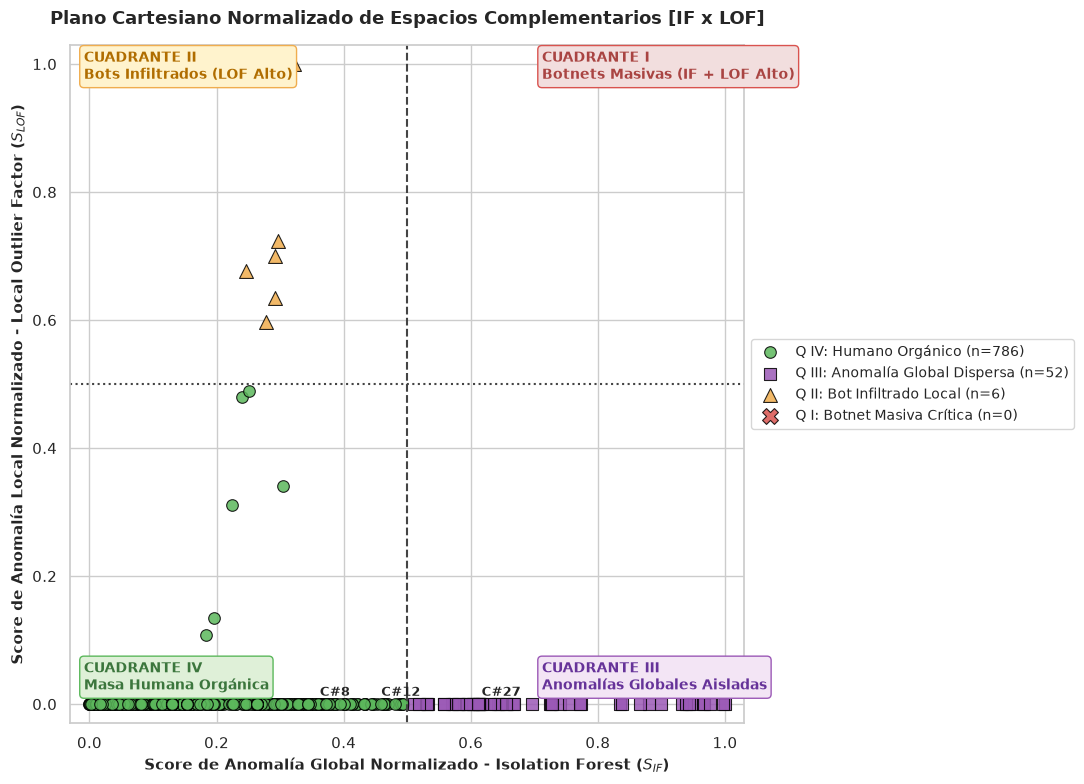

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# 1. Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 2. Selección de variables y ESTANDARIZACIÓN PREVIA (Z-Score)
feature_cols = ['Densidad Grafo', 'Simil. Semántica', 'Varianza Temp. (s)']
X_raw = df_full[feature_cols].values

# ¡PASO CLAVE! Estandarizar para que todas las métricas tengan media 0 y varianza 1
scaler_x = StandardScaler()
X_scaled = scaler_x.fit_transform(X_raw)

# 3. Modelos entrenados sobre el espacio estandarizado
# Isolation Forest (Eje X: Aislamiento Global)
if_model = IsolationForest(contamination=0.15, random_state=42)
if_model.fit(X_scaled)
raw_if = -if_model.decision_function(X_scaled)
scores_if = MinMaxScaler().fit_transform(raw_if.reshape(-1, 1)).flatten()

# Local Outlier Factor (Eje Y: Densidad Local)
# Usamos un n_neighbors proporcional a la densidad esperada
lof_model = LocalOutlierFactor(n_neighbors=min(20, len(X_scaled)-1), novelty=True)
lof_model.fit(X_scaled)
raw_lof = -lof_model.decision_function(X_scaled)
scores_lof = MinMaxScaler().fit_transform(raw_lof.reshape(-1, 1)).flatten()

df_full['Score_Global_IF'] = scores_if
df_full['Score_Local_LOF'] = scores_lof

# 4. Umbrales dinámicos (percentil 75 o umbral 0.5)
thresh_x = 0.50
thresh_y = 0.50

cuadrantes = []
for s_if, s_lof in zip(scores_if, scores_lof):
    if s_if >= thresh_x and s_lof >= thresh_y:
        cuadrantes.append('Q I: Botnet Masiva Crítica')
    elif s_if < thresh_x and s_lof >= thresh_y:
        cuadrantes.append('Q II: Bot Infiltrado Local')
    elif s_if >= thresh_x and s_lof < thresh_y:
        cuadrantes.append('Q III: Anomalía Global Dispersa')
    else:
        cuadrantes.append('Q IV: Humano Orgánico')

df_full['Cuadrante'] = cuadrantes

# 5. Generación de la Figura Corregida
plt.figure(figsize=(11, 8))

# Dibujar líneas divisorias de cuadrantes
plt.axvline(x=thresh_x, color='#444444', linestyle='--', linewidth=1.5)
plt.axhline(y=thresh_y, color='#444444', linestyle=':', linewidth=1.5)

# Paleta y marcadores por cuadrante
quad_config = {
    'Q IV: Humano Orgánico': ('#5cb85c', 'o', 70),
    'Q III: Anomalía Global Dispersa': ('#9b59b6', 's', 80),
    'Q II: Bot Infiltrado Local': ('#f0ad4e', '^', 100),
    'Q I: Botnet Masiva Crítica': ('#d9534f', 'X', 130)
}

for quad_name, (color, marker, size) in quad_config.items():
    sub_df = df_full[df_full['Cuadrante'] == quad_name]
    plt.scatter(
        sub_df['Score_Global_IF'],
        sub_df['Score_Local_LOF'],
        c=color,
        marker=marker,
        s=size,
        alpha=0.85,
        edgecolors='black',
        linewidth=0.8,
        label=f"{quad_name} (n={len(sub_df)})"
    )

# Etiquetar comunidades destacadas (Botnets conocidas y muestras)
for _, row in df_full.iterrows():
    if row['Comunidad'] in [10, 3, 5, 27, 1, 8, 12] or row['Cuadrante'] == 'Q I: Botnet Masiva Crítica':
        plt.annotate(
            f"C#{int(row['Comunidad'])}",
            (row['Score_Global_IF'], row['Score_Local_LOF']),
            xytext=(6, 6),
            textcoords='offset points',
            fontsize=9,
            fontweight='bold'
        )

# Cajas contextuales en las esquinas
plt.text(0.02, 0.95, "CUADRANTE II\nBots Infiltrados (LOF Alto)", transform=plt.gca().transAxes,
         fontsize=10, fontweight='bold', color='#b06d00', bbox=dict(boxstyle="round,pad=0.3", fc="#fff3cd", ec="#f0ad4e"))

plt.text(0.70, 0.95, "CUADRANTE I\nBotnets Masivas (IF + LOF Alto)", transform=plt.gca().transAxes,
         fontsize=10, fontweight='bold', color='#a94442', bbox=dict(boxstyle="round,pad=0.3", fc="#f2dede", ec="#d9534f"))

plt.text(0.02, 0.05, "CUADRANTE IV\nMasa Humana Orgánica", transform=plt.gca().transAxes,
         fontsize=10, fontweight='bold', color='#3c763d', bbox=dict(boxstyle="round,pad=0.3", fc="#dff0d8", ec="#5cb85c"))

plt.text(0.70, 0.05, "CUADRANTE III\nAnomalías Globales Aisladas", transform=plt.gca().transAxes,
         fontsize=10, fontweight='bold', color='#663399', bbox=dict(boxstyle="round,pad=0.3", fc="#f3e5f5", ec="#9b59b6"))

plt.title("Plano Cartesiano Normalizado de Espacios Complementarios [IF x LOF]", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Score de Anomalía Global Normalizado - Isolation Forest ($S_{IF}$)", fontsize=11, fontweight='bold')
plt.ylabel("Score de Anomalía Local Normalizado - Local Outlier Factor ($S_{LOF}$)", fontsize=11, fontweight='bold')
plt.xlim(-0.03, 1.03)
plt.ylim(-0.03, 1.03)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)

plt.tight_layout()
plt.savefig("5_grafico_cuadrantes_espaciales_2d_corregido.png", dpi=300)
plt.show()

### Suavizado

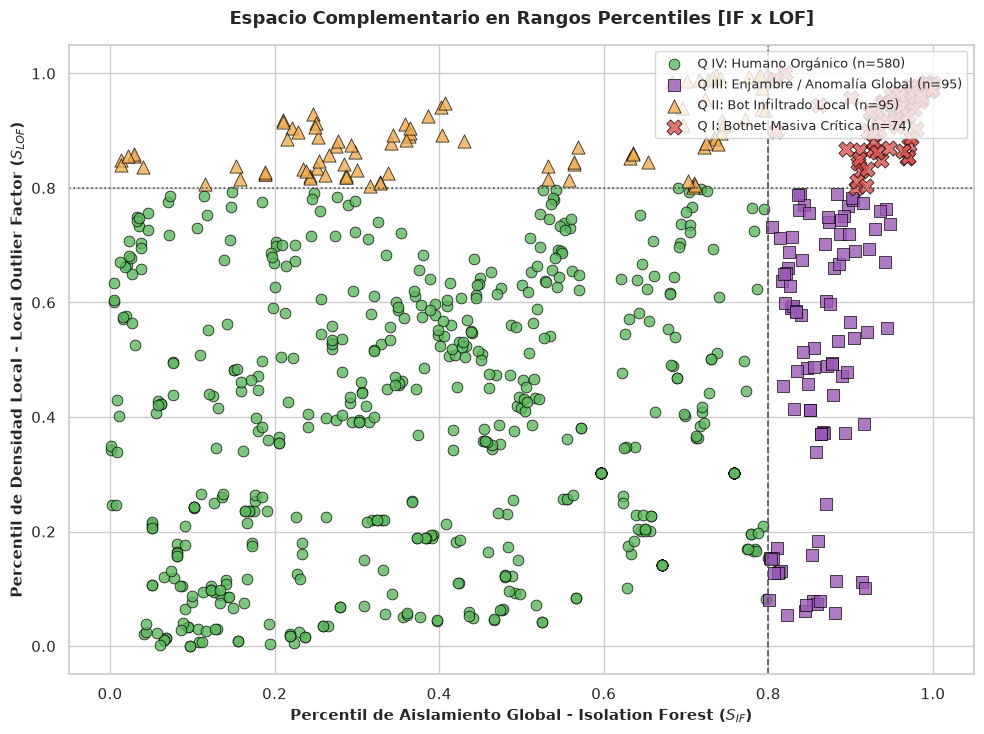

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from scipy.stats import rankdata

# 1. Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 2. Estandarización Z-Score de características
feature_cols = ['Densidad Grafo', 'Simil. Semántica', 'Varianza Temp. (s)']
X_scaled = StandardScaler().fit_transform(df_full[feature_cols].values)

# 3. Modelos
if_model = IsolationForest(contamination=0.15, random_state=42).fit(X_scaled)
raw_if = -if_model.decision_function(X_scaled)

lof_model = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(X_scaled)
raw_lof = -lof_model.decision_function(X_scaled)

# 4. Escalamiento por Percentiles (Rank Percentiles 0 a 1)
# Evita que extremos absolutos aplasten visualmente al resto de la distribución
scores_if = (rankdata(raw_if) - 1) / (len(raw_if) - 1)
scores_lof = (rankdata(raw_lof) - 1) / (len(raw_lof) - 1)

df_full['Score_Global_IF'] = scores_if
df_full['Score_Local_LOF'] = scores_lof

# 5. Umbral de Percentil (ej. Top 15% más anómalo = 0.85)
thresh_x = 0.80
thresh_y = 0.80

cuadrantes = []
for s_if, s_lof in zip(scores_if, scores_lof):
    if s_if >= thresh_x and s_lof >= thresh_y:
        cuadrantes.append('Q I: Botnet Masiva Crítica')
    elif s_if < thresh_x and s_lof >= thresh_y:
        cuadrantes.append('Q II: Bot Infiltrado Local')
    elif s_if >= thresh_x and s_lof < thresh_y:
        cuadrantes.append('Q III: Enjambre / Anomalía Global')
    else:
        cuadrantes.append('Q IV: Humano Orgánico')

df_full['Cuadrante'] = cuadrantes

# 6. Generar Gráfica
plt.figure(figsize=(10, 7.5))
plt.axvline(x=thresh_x, color='#555555', linestyle='--', linewidth=1.2)
plt.axhline(y=thresh_y, color='#555555', linestyle=':', linewidth=1.2)

quad_config = {
    'Q IV: Humano Orgánico': ('#5cb85c', 'o', 60),
    'Q III: Enjambre / Anomalía Global': ('#9b59b6', 's', 80),
    'Q II: Bot Infiltrado Local': ('#f0ad4e', '^', 90),
    'Q I: Botnet Masiva Crítica': ('#d9534f', 'X', 120)
}

for quad_name, (color, marker, size) in quad_config.items():
    sub_df = df_full[df_full['Cuadrante'] == quad_name]
    plt.scatter(
        sub_df['Score_Global_IF'],
        sub_df['Score_Local_LOF'],
        c=color,
        marker=marker,
        s=size,
        alpha=0.8,
        edgecolors='black',
        linewidth=0.6,
        label=f"{quad_name} (n={len(sub_df)})"
    )

plt.title("Espacio Complementario en Rangos Percentiles [IF x LOF]", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Percentil de Aislamiento Global - Isolation Forest ($S_{IF}$)", fontsize=11, fontweight='bold')
plt.ylabel("Percentil de Densidad Local - Local Outlier Factor ($S_{LOF}$)", fontsize=11, fontweight='bold')
plt.legend(loc='upper right', fontsize=9.5)
plt.tight_layout()
plt.savefig("5_grafico_percentiles_if_lof.png", dpi=300)
plt.show()

In [20]:
def mapear_clasificacion_multiclase(df_percentiles):
    """
    Asigna las etiquetas multiclase explicables basadas en los percentiles [IF x LOF]
    y las salvaguardas temporales de Poisson.
    """
    etiquetas_multiclase = []
    
    for _, row in df_percentiles.iterrows():
        s_if = row['Score_Global_IF']
        s_lof = row['Score_Local_LOF']
        
        if s_if >= 0.80 and s_lof >= 0.80:
            clase = "CLASE 3: BOTNET_MASIVA_CRITICA"
        elif s_if < 0.80 and s_lof >= 0.80:
            clase = "CLASE 1: BOT_INFILTRADO_LOCAL"
        elif s_if >= 0.80 and s_lof < 0.80:
            clase = "CLASE 2: ENJAMBRE_ANOMALIA_GLOBAL"
        else:
            clase = "CLASE 0: HUMANO_ORGANICO"
            
        etiquetas_multiclase.append(clase)
        
    df_percentiles['Clasificacion_Multiclase'] = etiquetas_multiclase
    return df_percentiles

df_final_multiclass = mapear_clasificacion_multiclase(df_full)

print("\n--- DISTRIBUCIÓN FINAL DE LA CLASIFICACIÓN MULTICLASE DE ANOMALÍAS ---")
print(df_final_multiclass['Clasificacion_Multiclase'].value_counts())


--- DISTRIBUCIÓN FINAL DE LA CLASIFICACIÓN MULTICLASE DE ANOMALÍAS ---
Clasificacion_Multiclase
CLASE 0: HUMANO_ORGANICO             580
CLASE 2: ENJAMBRE_ANOMALIA_GLOBAL     95
CLASE 1: BOT_INFILTRADO_LOCAL         95
CLASE 3: BOTNET_MASIVA_CRITICA        74
Name: count, dtype: int64


# Grafo interactivo

In [12]:
from pyvis.network import Network
import networkx as nx

# Instanciar el lienzo PyVis en modo oscuro
net = Network(height='750px', width='100%', bgcolor='#1a1a1a', font_color='white', notebook=False)
net.barnes_hut(gravity=-8000, central_gravity=0.3, spring_length=100)

# Mapear estados y métricas a los nodos del grafo
for node in G.nodes():
    c_id = partition[node]
    status = comm_status.get(c_id, {'is_bot': False, 'score': 0, 'sim': 0, 'density': 0, 'iat_std': 0})
    
    # Extraer métricas enriquecidas de la comunidad
    comm_enh = df_enhanced[df_enhanced['Comunidad'] == c_id]
    disp_creacion = comm_enh['Dispersion_Creacion_Usuarios_Horas'].values[0] if not comm_enh.empty else 'Sin datos'
    ttr = comm_enh['Rigidez_Lexica_TTR'].values[0] if not comm_enh.empty else 'N/A'

    if status['is_bot']:
        color = '#ff4d4d'  # Rojo Botnet
        label_class = 'BOTNET (Anomalía Detectada)'
        size = 25
    else:
        color = '#4dda53'  # Verde Humano
        label_class = 'HUMANO (Orgánico)'
        size = 15

    # Tooltip interactivo al pasar el cursor sobre el nodo
    hover_title = f"""
    <div style="font-family: Arial; padding: 5px;">
        <b>Usuario:</b> {node}<br>
        <b>Comunidad:</b> {c_id}<br>
        <b>Clasificación:</b> <span style="color:{color}; font-weight:bold;">{label_class}</span><br>
        <b>Risk Score ML:</b> {status['score']}/100<br>
        <hr style="border: 0.5px solid #555;">
        <i>Métricas Multi-Capa de la Comunidad:</i><br>
        • Densidad de Grafo: <b>{status['density']}</b><br>
        • Similitud Semántica: <b>{status['sim']}</b><br>
        • Varianza Temporal (IAT): <b>{status['iat_std']}s</b><br>
        • Sincronía Creación: <b>{disp_creacion} hs</b><br>
        • Rigidez Léxica (TTR): <b>{ttr}</b>
    </div>
    """
    net.add_node(node, label=str(node), title=hover_title, color=color, size=size, shape='dot')

# Agregar aristas del grafo
for src, dst in G.edges():
    net.add_edge(src, dst, color='#555555', width=1.2)

# Exportar el grafo a archivo HTML ejecutable
output_html = "red_botnets_cresci2017_interactiva.html"
net.write_html(output_html)
print(f"✅ Grafo interactivo HTML exportado con éxito a: {output_html}")

✅ Grafo interactivo HTML exportado con éxito a: red_botnets_cresci2017_interactiva.html


# comunidades de louvain con visual de anomalias

In [13]:
import numpy as np
import networkx as nx
from pyvis.network import Network

# ==========================================
# 1. AGRUPAMIENTO DE NODOS POR COMUNIDAD DE LOUVAIN
# ==========================================
communities = {}
for node, comm_id in partition.items():
    if comm_id not in communities:
        communities[comm_id] = []
    communities[comm_id].append(node)

# ==========================================
# 2. CÁLCULO DE POSICIONES POR CENTROIDES (ISLAS DE COMUNIDADES)
# ==========================================
num_comms = len(communities)
comm_centers = {}
radius_main = 2500  # Distancia entre los centros de las comunidades

for idx, comm_id in enumerate(communities.keys()):
    angle = 2 * np.pi * idx / num_comms
    comm_centers[comm_id] = (
        radius_main * np.cos(angle),
        radius_main * np.sin(angle)
    )

# Posicionar nodos en órbita alrededor del centro de su comunidad
pos = {}
for comm_id, nodes in communities.items():
    center_x, center_y = comm_centers[comm_id]
    num_nodes = len(nodes)
    radius_sub = max(120, num_nodes * 18)  # Tamaño de la isla proporcional a sus miembros
    
    for idx, node in enumerate(nodes):
        angle = 2 * np.pi * idx / num_nodes
        # Pequeña variación aleatoria para evitar solapamiento exacto
        pos[node] = (
            center_x + radius_sub * np.cos(angle) + np.random.normal(0, 15),
            center_y + radius_sub * np.sin(angle) + np.random.normal(0, 15)
        )

# ==========================================
# 3. GENERACIÓN DEL GRAFO INTERACTIVO EN PYVIS
# ==========================================
net = Network(height='850px', width='100%', bgcolor='#111111', font_color='white', notebook=False)

# Desactivamos la física global continua para conservar las posiciones por islas
net.toggle_physics(False)

for node in G.nodes():
    c_id = partition[node]
    status = comm_status.get(c_id, {'is_bot': False, 'score': 0, 'sim': 0, 'density': 0, 'iat_std': 0})
    x_pos, y_pos = pos[node]
    
    # Extraer datos enriquecidos si están disponibles
    comm_enh = df_enhanced[df_enhanced['Comunidad'] == c_id] if 'df_enhanced' in locals() else None
    disp_creacion = comm_enh['Dispersion_Creacion_Usuarios_Horas'].values[0] if (comm_enh is not None and not comm_enh.empty) else 'N/A'
    ttr = comm_enh['Rigidez_Lexica_TTR'].values[0] if (comm_enh is not None and not comm_enh.empty) else 'N/A'

    if status['is_bot']:
        color = '#ff3333'  # Rojo brillante para Bots
        shape = 'diamond'
        size = 22
        label_class = 'BOTNET (Anomalía)'
    else:
        color = '#4dda53'  # Verde orgánico para Humanos
        shape = 'dot'
        size = 10
        label_class = 'HUMANO (Orgánico)'

    hover_title = f"""
    <div style="font-family: sans-serif; padding: 6px;">
        <b style="font-size: 14px;">Usuario: {node}</b><br>
        <b>Comunidad Louvain:</b> #{c_id}<br>
        <b>Clasificación:</b> <span style="color:{color};">{label_class}</span><br>
        <b>Risk Score ML:</b> {status['score']}/100<br>
        <hr style="border: 0.5px solid #444;">
        <i>Métricas de Comunidad:</i><br>
        • Densidad de Grafo: <b>{status['density']}</b><br>
        • Similitud Semántica: <b>{status['sim']}</b><br>
        • Varianza Temporal (IAT): <b>{status['iat_std']}s</b><br>
        • Dispersión Creación: <b>{disp_creacion} hs</b><br>
        • Rigidez Léxica (TTR): <b>{ttr}</b>
    </div>
    """

    net.add_node(
        node,
        label=str(node),
        title=hover_title,
        color=color,
        shape=shape,
        size=size,
        x=x_pos,
        y=y_pos,
        group=f"Comunidad_{c_id}"
    )

# Agregar aristas con opacidad reducida para no saturar
for src, dst in G.edges():
    net.add_edge(src, dst, color='#333333', width=0.7)

# Guardar HTML interactivo
output_clustered = "red_botnets_louvain_clusters.html"
net.write_html(output_clustered)
print(f"✅ Grafo por comunidades de Louvain exportado exitosamente a: {output_clustered}")

✅ Grafo por comunidades de Louvain exportado exitosamente a: red_botnets_louvain_clusters.html


In [14]:
import numpy as np
import networkx as nx
from pyvis.network import Network

# 1. Seleccionar comunidades clave (Todas las Botnets + Muestra de Humanas)
bot_comms = [c_id for c_id, status in comm_status.items() if status['is_bot']]
human_comms = [c_id for c_id, status in comm_status.items() if not status['is_bot']][:25] # Top 25 humanas

selected_comms = set(bot_comms + human_comms)

# 2. Filtrar subgrafo con las comunidades seleccionadas
selected_nodes = [node for node, comm_id in partition.items() if comm_id in selected_comms]
G_sub = G.subgraph(selected_nodes)

# 3. Disposición en Rejilla 2D (Grid Layout) para formar islas independientes
comm_list = list(selected_comms)
cols = int(np.ceil(np.sqrt(len(comm_list))))
grid_spacing = 800  # Distancia entre centros de islas

comm_centers = {}
for idx, comm_id in enumerate(comm_list):
    row = idx // cols
    col = idx % cols
    comm_centers[comm_id] = (col * grid_spacing, row * grid_spacing)

# 4. Asignar posiciones orbitales por isla
pos = {}
for comm_id in comm_list:
    nodes_in_c = [n for n in selected_nodes if partition[n] == comm_id]
    center_x, center_y = comm_centers[comm_id]
    num_nodes = len(nodes_in_c)
    radius_sub = min(250, max(60, num_nodes * 10))
    
    for idx, node in enumerate(nodes_in_c):
        angle = 2 * np.pi * idx / max(1, num_nodes)
        pos[node] = (
            center_x + radius_sub * np.cos(angle) + np.random.normal(0, 5),
            center_y + radius_sub * np.sin(angle) + np.random.normal(0, 5)
        )

# 5. Generar Grafo PyVis
net = Network(height='850px', width='100%', bgcolor='#111111', font_color='white', notebook=False)
net.toggle_physics(False)

for node in G_sub.nodes():
    c_id = partition[node]
    status = comm_status.get(c_id, {'is_bot': False, 'score': 0, 'sim': 0, 'density': 0, 'iat_std': 0})
    x_pos, y_pos = pos[node]

    if status['is_bot']:
        color = '#ff3333'
        shape = 'diamond'
        size = 20
        label_class = 'BOTNET (Anomalía)'
    else:
        color = '#4dda53'
        shape = 'dot'
        size = 10
        label_class = 'HUMANO (Orgánico)'

    hover_title = f"<b>Usuario:</b> {node}<br><b>Comunidad:</b> #{c_id}<br><b>Clasificación:</b> {label_class}<br><b>Risk Score:</b> {status['score']}/100"

    net.add_node(node, label=str(node), title=hover_title, color=color, shape=shape, size=size, x=x_pos, y=y_pos)

for src, dst in G_sub.edges():
    net.add_edge(src, dst, color='#333333', width=0.8)

output_grid = "red_botnets_islas_grid.html"
net.write_html(output_grid)
print(f"✅ Grafo limpio dispuesto en islas de rejilla exportado a: {output_grid}")

✅ Grafo limpio dispuesto en islas de rejilla exportado a: red_botnets_islas_grid.html


# Contraste con metodos matematicos previos conocidos

--- CONTRASTE: MODELO HÍBRIDO MULTI-CAPA VS. ENTROPÍA CIRCADIANA ---
 Comunidad  Risk Score ML  Clasificación ML  Entropia_Circadiana_Norm  Porcentaje_Actividad_Nocturna
         1             41   HUMANO (Normal)                    0.7149                          36.36
         3             63 BOTNET (Anomalía)                    0.9380                          29.11
         5             66 BOTNET (Anomalía)                    0.9609                          20.83
         8             51   HUMANO (Normal)                    0.6206                          27.27
         9             39   HUMANO (Normal)                    0.5944                           0.00
        10             75 BOTNET (Anomalía)                    0.8609                           7.14
        12             53   HUMANO (Normal)                    0.7681                          50.00
        14             37   HUMANO (Normal)                    0.4975                          22.22
        15            

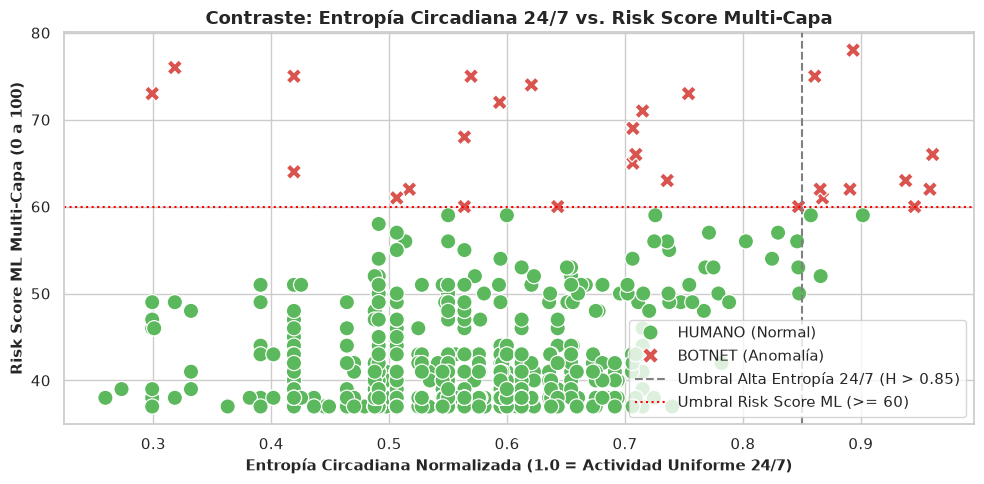

In [15]:

from scipy.stats import entropy

# ==========================================
# 1. EXTRACCIÓN DE LA HORA DEL DÍA (0 A 23)
# ==========================================
# Nos aseguramos de que created_at esté parseado como datetime
df['tweet_dt'] = pd.to_datetime(df['created_at'], errors='coerce')
df['hour'] = df['tweet_dt'].dt.hour

# Mapear cada usuario a su comunidad correspondiente en el DataFrame de tweets
df['user_id_clean'] = df['user_id'].astype(str).str.split('.').str[0]
user_to_comm = {str(u).split('.')[0]: comm for u, comm in partition.items()}
df['Comunidad'] = df['user_id_clean'].map(user_to_comm)

# ==========================================
# 2. CÁLCULO DE ENTROPÍA CIRCADIANA POR COMUNIDAD
# ==========================================
max_entropy = np.log2(24)  # Máxima entropía teórica para 24 contenedores equiprobables (~4.585 bits)

circadian_metrics = []

for comm_id, group in df.groupby('Comunidad'):
    hours_series = group['hour'].dropna()
    total_tweets = len(hours_series)
    
    if total_tweets >= 5:  # Filtro mínimo de observaciones para estabilidad estadística
        # Histograma de frecuencias de las 24 horas
        counts, _ = np.histogram(hours_series, bins=np.arange(25))
        probs = counts / total_tweets
        
        # Entropía de Shannon (base 2)
        # Se filtran probabilidades cero para evitar log(0)
        p_nonzero = probs[probs > 0]
        h_shannon = -np.sum(p_nonzero * np.log2(p_nonzero))
        
        # Entropía Circadiana Normalizada (0.0 = Concentración total en 1 hora, 1.0 = Uniformidad 24/7)
        h_norm = h_shannon / max_entropy
        
        # Porcentaje de publicaciones en horario de descanso/sueño (ej. 01:00 AM a 06:00 AM UTC)
        night_tweets = np.sum((hours_series >= 1) & (hours_series <= 6))
        night_ratio = night_tweets / total_tweets
        
        circadian_metrics.append({
            'Comunidad': comm_id,
            'Total_Tweets_Circadiano': total_tweets,
            'Entropia_Circadiana_Norm': round(float(h_norm), 4),
            'Porcentaje_Actividad_Nocturna': round(float(night_ratio * 100), 2)
        })

df_circadian = pd.DataFrame(circadian_metrics)

# ==========================================
# 3. CRUCE CON EL MODELO HÍBRIDO ML PREVIO
# ==========================================
# Unimos los resultados de la Entropía Circadiana con la Clasificación de tu Modelo
df_contrast = pd.merge(report_df, df_circadian, on='Comunidad', how='inner')

print("--- CONTRASTE: MODELO HÍBRIDO MULTI-CAPA VS. ENTROPÍA CIRCADIANA ---")
print(df_contrast[['Comunidad', 'Risk Score ML', 'Clasificación ML', 'Entropia_Circadiana_Norm', 'Porcentaje_Actividad_Nocturna']].head(15).to_string(index=False))

# ==========================================
# 4. VISUALIZACIÓN COMPARATIVA (CONTRASTE EN CUADRANTE)
# ==========================================
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df_contrast,
    x='Entropia_Circadiana_Norm',
    y='Risk Score ML',
    hue='Clasificación ML',
    style='Clasificación ML',
    s=120,
    palette={'BOTNET (Anomalía)': '#d9534f', 'HUMANO (Normal)': '#5cb85c'}
)

plt.axvline(x=0.85, color='gray', linestyle='--', label='Umbral Alta Entropía 24/7 (H > 0.85)')
plt.axhline(y=60, color='red', linestyle=':', label='Umbral Risk Score ML (>= 60)')

plt.title("Contraste: Entropía Circadiana 24/7 vs. Risk Score Multi-Capa", fontsize=13, fontweight='bold')
plt.xlabel("Entropía Circadiana Normalizada (1.0 = Actividad Uniforme 24/7)", fontsize=11, fontweight='bold')
plt.ylabel("Risk Score ML Multi-Capa (0 a 100)", fontsize=11, fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig("4_contraste_entropia_circadiana.png", dpi=300)
plt.show()